# Bab 7 — Support Vector Machines and Kernel Methods

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt, 2025)

---

| No | Resep | Dataset | Inti |
|----|-------|---------|------|
| 1 | Pengantar SVM | Iris | `SVC` (klasifikasi) dan `SVR` (regresi), margin, support vector |
| 2 | Fungsi kernel | Iris | linear vs polinomial vs RBF, batas keputusan 2D |
| 3 | Tuning parameter SVM | Iris | `GridSearchCV` untuk `C`, `kernel`, `degree`; pengaruh `C` |
| 4 | SVM di ruang berdimensi tinggi | sintetis 1000 fitur | data "lebar" ($p \approx n$) |
| 5 | Evaluasi model SVM | Breast Cancer | classification report, ROC–AUC, `probability=True` |
| 6 | Latihan | Iris, Breast Cancer, sintetis 2D | |

In [ ]:
import numpy as np
import warnings
warnings.filterwarnings('ignore')

## Resep 1 — Pengantar SVM

### Teori: Hard-margin SVM
Untuk data biner $y_i\in\{-1,+1\}$ yang terpisah linear, hyperplane $\mathbf w^\top\mathbf x + b = 0$ memisahkan kelas jika $y_i(\mathbf w^\top\mathbf x_i + b) > 0$ untuk semua $i$. Jarak titik ke hyperplane adalah $|\mathbf w^\top\mathbf x + b|/\lVert\mathbf w\rVert$. Dengan menormalisasi sehingga titik terdekat memenuhi $y_i(\mathbf w^\top\mathbf x_i+b) = 1$, lebar margin menjadi $2/\lVert\mathbf w\rVert$. Memaksimalkan margin setara dengan:
$$\min_{\mathbf w, b}\; \frac12\lVert\mathbf w\rVert^2 \quad\text{s.t.}\quad y_i(\mathbf w^\top\mathbf x_i+b)\ge 1,\;\; i=1,\dots,n$$

### Soft-margin SVM
Data nyata jarang terpisah sempurna, sehingga ditambahkan variabel *slack* $\xi_i \ge 0$ yang mengizinkan pelanggaran margin:
$$\min_{\mathbf w,b,\boldsymbol\xi}\; \frac12\lVert\mathbf w\rVert^2 + C\sum_{i=1}^{n}\xi_i \quad\text{s.t.}\quad y_i(\mathbf w^\top\mathbf x_i+b)\ge 1-\xi_i$$
Ini setara dengan meminimalkan **hinge loss** $\sum_i\max(0,\,1-y_i f(\mathbf x_i))$ plus penalti L2. Parameter **$C$** mengatur kompromi: $C$ besar → hampir tidak boleh ada pelanggaran (margin sempit, rawan overfitting); $C$ kecil → margin lebar, lebih banyak pelanggaran ditoleransi (lebih teregularisasi).

### Support vectors
Dari formulasi dual (lihat Resep 2), solusinya berbentuk $\mathbf w = \sum_i \alpha_i y_i\mathbf x_i$ dengan $\alpha_i > 0$ **hanya** untuk titik yang berada di margin atau melanggarnya. Titik-titik itulah **support vectors** — model hanya bergantung pada mereka; titik lain bisa dihapus tanpa mengubah batas keputusan.

### Support Vector Regression (SVR)
SVR memakai **$\varepsilon$-insensitive loss**: galat lebih kecil dari $\varepsilon$ tidak dihukum sama sekali, sehingga model mencari fungsi yang "setipis mungkin" (kecil $\lVert\mathbf w\rVert$) dan sebagian besar titik berada di dalam "tabung" selebar $\pm\varepsilon$:
$$L_\varepsilon(y, f(\mathbf x)) = \max(0,\; |y - f(\mathbf x)| - \varepsilon)$$

SVM untuk multikelas: `SVC` di scikit-learn memakai strategi **One-vs-One** — melatih $K(K-1)/2$ classifier biner (untuk Iris: 3), lalu voting.

In [ ]:
# Load libraries
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC, SVR
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

### SVM untuk klasifikasi (kernel linear)

In [ ]:
# Load the model
svm_classifier = SVC(kernel='linear')

# Train the model
svm_classifier.fit(X_train, y_train)

# Make predictions
y_pred = svm_classifier.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

# Stylize the DataFrame
styled_df = (report_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

print(f"Accuracy: {accuracy:.2f}")
styled_df

Accuracy: 0.93


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.909,0.833,0.870,12
2,0.875,0.933,0.903,15
accuracy,0.933,0.933,0.933,1
macro avg,0.928,0.922,0.924,45
weighted avg,0.934,0.933,0.933,45


In [ ]:
# Inspeksi support vectors
print('Jumlah support vector per kelas:', svm_classifier.n_support_)
print('Total support vector: %d dari %d sampel latih' % (svm_classifier.n_support_.sum(), len(X_train)))

Jumlah support vector per kelas: [ 3 10  8]
Total support vector: 21 dari 105 sampel latih


**Interpretasi.** SVM linear mencapai akurasi 0,93 (42 dari 45). Yang menarik: dari 105 sampel latih, hanya **21** yang menjadi support vector (3 untuk *setosa*, 10 untuk *versicolor*, 8 untuk *virginica*). Artinya ≈80% data latih bisa dihapus tanpa mengubah batas keputusan. *Setosa* hanya butuh 3 support vector karena terpisah jauh dari kelas lain, sedangkan *versicolor* dan *virginica* yang saling berdekatan membutuhkan lebih banyak titik untuk mendefinisikan batasnya.

### SVM untuk regresi (SVR, kernel RBF)
Kode buku memakai label kelas Iris (0, 1, 2) sebagai target numerik dan hanya dua fitur pertama (*sepal length* dan *sepal width*). Ini bukan masalah regresi yang alami — tujuannya hanya mendemonstrasikan API `SVR`.

In [ ]:
# Load the model
svm_regressor = SVR(kernel='rbf')

# Train the model
svm_regressor.fit(X_train[:, :2], y_train)

# Make predictions
y_pred_reg = svm_regressor.predict(X_test[:, :2])

# Evaluate the model
# Note: For regression, we typically use metrics like MSE or R-squared
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test, y_pred_reg)
print(f"MSE: {mse:.2f}")

MSE: 0.20


In [ ]:
from sklearn.metrics import r2_score
print('R^2 SVR: %.3f' % r2_score(y_test, y_pred_reg))
print('Varians target uji (MSE jika selalu memprediksi rata-rata): %.3f' % np.var(y_test))

R^2 SVR: 0.721
Varians target uji (MSE jika selalu memprediksi rata-rata): 0.729


**Interpretasi.** MSE SVR = 0,20, sedangkan "model" yang selalu menebak rata-rata akan memiliki MSE sebesar varians target. $R^2$ ≈ 0,72 berarti SVR menjelaskan sekitar 72% variasi label hanya dari dua fitur sepal. Namun karena target sebenarnya adalah **kategori**, pendekatan klasifikasi (`SVC`) lebih tepat secara konseptual; contoh ini hanya untuk memperkenalkan `SVR`.

### Visualisasi
Plot berikut menampilkan permukaan prediksi SVR di bidang *sepal length × sepal width*. Karena SVR menghasilkan nilai kontinu, warna latar menunjukkan "nilai kelas" yang diprediksi, bukan kelas diskrit.

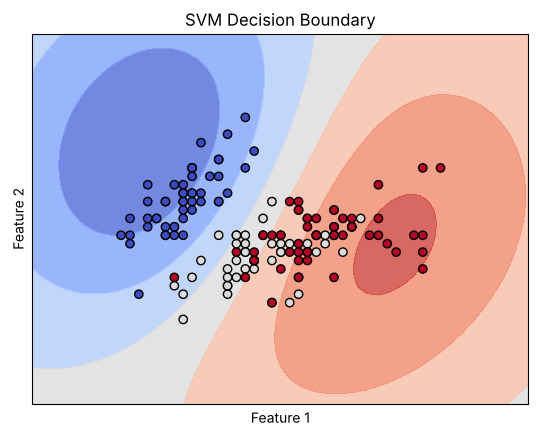

In [ ]:
# Load the libraries
import matplotlib.pyplot as plt
import numpy as np
from sklearn.inspection import DecisionBoundaryDisplay

# Create a mesh grid
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Adjust the input to match the expected number of features
# Use all four features for prediction, but only visualize the first two
grid_points = np.c_[xx.ravel(), yy.ravel(), np.zeros((xx.ravel().shape[0], 2))]

# Plot decision boundaries using DecisionBoundaryDisplay
fig, ax = plt.subplots()
disp = DecisionBoundaryDisplay.from_estimator(
    svm_regressor,
    grid_points[:, :2],
    response_method="predict",
    plot_method="contourf",
    cmap=plt.cm.coolwarm,
    alpha=0.8,
    ax=ax
)

# Plot the data points
ax.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o', cmap=plt.cm.coolwarm)
ax.set_title("SVM Decision Boundary")
ax.set_xlabel("Feature 1")
ax.set_ylabel("Feature 2")
ax.set_xlim(xx.min(), xx.max())
ax.set_ylim(yy.min(), yy.max())
ax.set_xticks(())
ax.set_yticks(())
plt.show()

**Interpretasi.** Permukaan prediksi berubah secara halus (ciri kernel RBF), dari nilai rendah (≈0, *setosa*) di area sepal pendek dan lebar menuju nilai tinggi (≈2, *virginica*) di area sepal panjang. Titik-titik *versicolor* dan *virginica* saling bertumpuk di bidang sepal, sehingga batas di antara keduanya tidak tegas — hal ini menjelaskan MSE dan $R^2$ yang kurang baik di atas.

## Resep 2 — Fungsi Kernel dan Aplikasinya

### Teori: Formulasi dual dan kernel trick
Dengan pengali Lagrange, masalah soft-margin dapat ditulis dalam **bentuk dual**:
$$\max_{\boldsymbol\alpha}\; \sum_i\alpha_i - \frac12\sum_{i,j}\alpha_i\alpha_j y_iy_j\,\mathbf x_i^\top\mathbf x_j \quad\text{s.t.}\quad 0\le\alpha_i\le C,\;\; \sum_i\alpha_iy_i=0$$
dan fungsi keputusannya
$$f(\mathbf x) = \operatorname{sign}\Big(\sum_{i\in SV}\alpha_iy_i\,\mathbf x_i^\top\mathbf x + b\Big).$$

Data **hanya muncul dalam bentuk perkalian titik** $\mathbf x_i^\top\mathbf x_j$. Jika kita memetakan data ke ruang fitur $\phi(\mathbf x)$ berdimensi tinggi (bahkan tak hingga), cukup ganti perkalian titik dengan **fungsi kernel**
$$K(\mathbf x, \mathbf x') = \phi(\mathbf x)^\top\phi(\mathbf x'),$$
tanpa pernah menghitung $\phi$ secara eksplisit. Inilah **kernel trick**. Syaratnya: $K$ harus simetris dan matriks Gram-nya semi-definit positif (**teorema Mercer**).

| Kernel | Rumus | Parameter | Karakter batas keputusan |
|---|---|---|---|
| Linear | $\mathbf x^\top\mathbf x'$ | – | hyperplane |
| Polinomial | $(\gamma\,\mathbf x^\top\mathbf x' + r)^d$ | `degree`, `gamma`, `coef0` | kurva polinomial derajat $d$ |
| RBF (Gaussian) | $\exp(-\gamma\lVert\mathbf x-\mathbf x'\rVert^2)$ | `gamma` | sangat fleksibel, lokal |
| Sigmoid | $\tanh(\gamma\,\mathbf x^\top\mathbf x' + r)$ | `gamma`, `coef0` | mirip neural network sederhana |

**Peran $\gamma$ pada RBF:** $\gamma$ besar → kernel sangat sempit, setiap support vector hanya memengaruhi area kecil di sekitarnya → batas keputusan berliku (overfitting). $\gamma$ kecil → pengaruh luas, batas halus (mendekati linear). Default `gamma='scale'` = $1/(p\cdot\operatorname{Var}(\mathbf X))$.

Karena RBF dan polinomial bergantung pada jarak/perkalian titik, **SVM sensitif terhadap skala fitur** — standardisasi sangat dianjurkan.

In [ ]:
# Load the libraries
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

### Kernel polinomial (derajat 3)

In [ ]:
# Load the model
svm_poly = SVC(kernel='poly', degree=3)

# Train the model
svm_poly.fit(X_train, y_train)

# Make predictions
y_pred_poly = svm_poly.predict(X_test)

# Evaluate the model
accuracy_poly = accuracy_score(y_test, y_pred_poly)
report_poly = classification_report(y_test, y_pred_poly, output_dict=True)
report_df_poly = pd.DataFrame(report_poly).transpose()

# Stylize the DataFrame
styled_df_poly = (report_df_poly
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

print(f"Polynomial Kernel Accuracy: {accuracy_poly:.2f}")
styled_df_poly

Polynomial Kernel Accuracy: 0.96


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,1.000,0.833,0.909,12
2,0.882,1.000,0.938,15
accuracy,0.956,0.956,0.956,1
macro avg,0.961,0.944,0.949,45
weighted avg,0.961,0.956,0.955,45


### Kernel RBF

In [ ]:
# Load the model
svm_rbf = SVC(kernel='rbf')

# Train the model
svm_rbf.fit(X_train, y_train)

# Make predictions
y_pred_rbf = svm_rbf.predict(X_test)

# Evaluate the model
accuracy_rbf = accuracy_score(y_test, y_pred_rbf)
report_rbf = classification_report(y_test, y_pred_rbf, output_dict=True)
report_df_rbf = pd.DataFrame(report_rbf).transpose()

# Stylize the DataFrame
styled_df_rbf = (report_df_rbf
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

print(f"RBF Kernel Accuracy: {accuracy_rbf:.2f}")
styled_df_rbf

RBF Kernel Accuracy: 0.91


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.786,0.917,0.846,12
2,0.923,0.800,0.857,15
accuracy,0.911,0.911,0.911,1
macro avg,0.903,0.906,0.901,45
weighted avg,0.917,0.911,0.911,45


### Batas keputusan setiap kernel (2 fitur pertama)

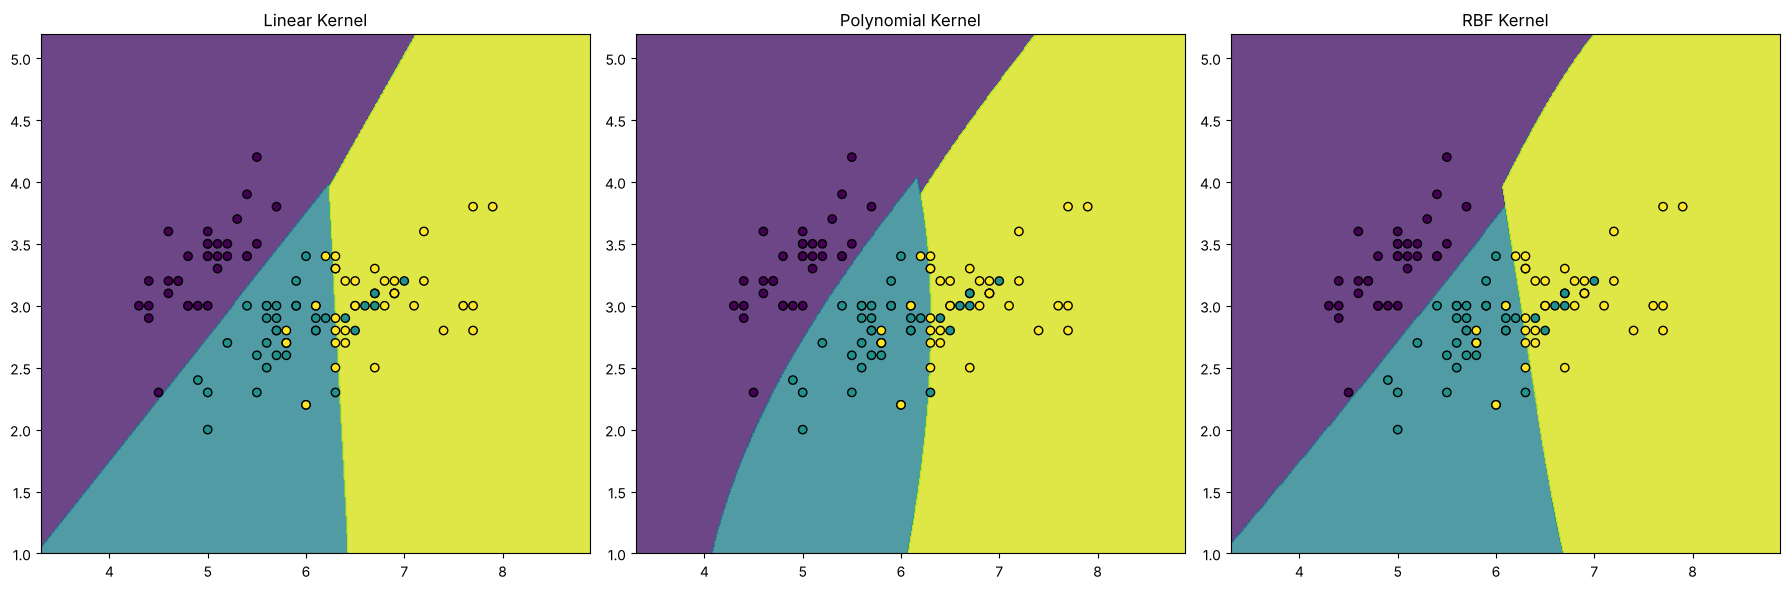

In [ ]:
# Create a mesh grid using only the first two features for visualization
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Use only the first two features for prediction
X_train_2d = X_train[:, :2]

# Train new SVM models using only the first two features
svm_linear_2d = SVC(kernel='linear').fit(X_train_2d, y_train)
svm_poly_2d = SVC(kernel='poly').fit(X_train_2d, y_train)
svm_rbf_2d = SVC(kernel='rbf').fit(X_train_2d, y_train)

# Predict class probabilities across the grid for each kernel using only the first two features
Z_linear = svm_linear_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z_poly = svm_poly_2d.predict(np.c_[xx.ravel(), yy.ravel()])
Z_rbf = svm_rbf_2d.predict(np.c_[xx.ravel(), yy.ravel()])

Z_linear = Z_linear.reshape(xx.shape)
Z_poly = Z_poly.reshape(xx.shape)
Z_rbf = Z_rbf.reshape(xx.shape)

# Plot decision boundaries
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].contourf(xx, yy, Z_linear, alpha=0.8)
axes[0].scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, edgecolors='k', marker='o')
axes[0].set_title("Linear Kernel")

axes[1].contourf(xx, yy, Z_poly, alpha=0.8)
axes[1].scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, edgecolors='k', marker='o')
axes[1].set_title("Polynomial Kernel")

axes[2].contourf(xx, yy, Z_rbf, alpha=0.8)
axes[2].scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train, edgecolors='k', marker='o')
axes[2].set_title("RBF Kernel")

plt.tight_layout()
plt.show()

In [ ]:
# Akurasi model 2D (hanya sepal length & sepal width) pada data uji
X_test_2d = X_test[:, :2]
for name, m in [('Linear', svm_linear_2d), ('Polynomial', svm_poly_2d), ('RBF', svm_rbf_2d)]:
    print(f'{name:<10} akurasi 2D: {m.score(X_test_2d, y_test):.3f} | support vectors: {m.n_support_.sum()}')

Linear     akurasi 2D: 0.800 | support vectors: 63
Polynomial akurasi 2D: 0.778 | support vectors: 48
RBF        akurasi 2D: 0.800 | support vectors: 74


**Interpretasi.**
- Dengan **4 fitur**, kernel polinomial memberi akurasi tertinggi (0,96), disusul linear (0,93) dan RBF (0,91). Selisihnya hanya 1–2 sampel dari 45, jadi pada Iris ketiga kernel praktis setara; data yang mudah dipisahkan tidak membutuhkan kernel yang kompleks.
- Dengan hanya **2 fitur sepal**, akurasi turun ke ≈0,78–0,80 untuk semua kernel, karena *versicolor* dan *virginica* bertumpuk di bidang sepal. Pada gambar: kernel linear menghasilkan batas berupa garis lurus, polinomial berupa kurva halus, dan RBF berupa daerah yang lebih "membulat" mengikuti kelompok data.
- Jumlah support vector pada model 2D jauh lebih banyak (48–74 dari 105) dibanding model 4D (21), karena kelas yang saling tumpang tindih membuat banyak titik berada di dalam atau melanggar margin.

## Resep 3 — Tuning Parameter SVM

### Teori
Hyperparameter terpenting SVM:
- **`C`** — kompromi margin vs kesalahan latih (lihat Resep 1).
- **`kernel`** — bentuk batas keputusan.
- **`gamma`** (RBF/poly/sigmoid) — jangkauan pengaruh setiap support vector.
- **`degree`** (poly) — derajat polinomial.

Untuk kernel RBF, `C` dan `gamma` saling berinteraksi kuat, sehingga sebaiknya dicari bersamaan dalam skala logaritmik (misal $C\in\{10^{-3},\dots,10^{3}\}$). Catatan tentang grid buku: parameter `degree` hanya berpengaruh untuk kernel `poly`; kombinasi `degree` dengan kernel `linear`/`rbf` menghasilkan model identik sehingga grid ini mengandung pengulangan (3 × 3 × 3 = 27 kombinasi, padahal hanya 15 model berbeda).

In [ ]:
# Load the libraries
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [ ]:
# Define the parameter grid
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf', 'poly'],
    'degree': [2, 3, 4]
}

# Perform grid search with cross-validation
grid_search = GridSearchCV(SVC(), param_grid, cv=5)
grid_search.fit(X_train, y_train)

# Get the best hyperparameters and score
best_params = grid_search.best_params_
best_score = grid_search.best_score_
print(f"Best Parameters: {best_params}")
print(f"Best Cross-Validation Score: {best_score:.2f}")

# Train a new model with the best hyperparameters
best_model = SVC(**best_params)
best_model.fit(X_train, y_train)

# Make predictions with the best model
y_pred = best_model.predict(X_test)

# Evaluate the best model
accuracy = accuracy_score(y_test, y_pred)
report_df = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).transpose()

# Stylize the DataFrame
styled_report_df = (report_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

print(f"Accuracy: {accuracy:.2f}")
styled_report_df

Best Parameters: {'C': 0.1, 'degree': 4, 'kernel': 'poly'}
Best Cross-Validation Score: 0.99
Accuracy: 0.93


,precision,recall,f1-score,support
0,1.000,1.000,1.000,18
1,0.909,0.833,0.870,12
2,0.875,0.933,0.903,15
accuracy,0.933,0.933,0.933,1
macro avg,0.928,0.922,0.924,45
weighted avg,0.934,0.933,0.933,45


**Interpretasi.** Grid search memilih `C=0.1`, `kernel='poly'`, `degree=4` dengan skor CV ≈ 0,99, tetapi akurasi pada data uji 0,93 — lebih rendah dari kernel poly default pada Resep 2 (0,96). Ini contoh bahwa skor CV terbaik tidak selalu menghasilkan skor uji terbaik: banyak kombinasi memiliki skor CV hampir sama pada data sekecil ini (105 sampel latih), dan pemilihan di antara kombinasi yang hampir seri sangat dipengaruhi kebetulan. Data uji yang hanya 45 sampel juga membuat selisih 1 sampel = 2,2 poin persentase.

### Pengaruh $C$ terhadap skor cross-validation (kernel RBF)

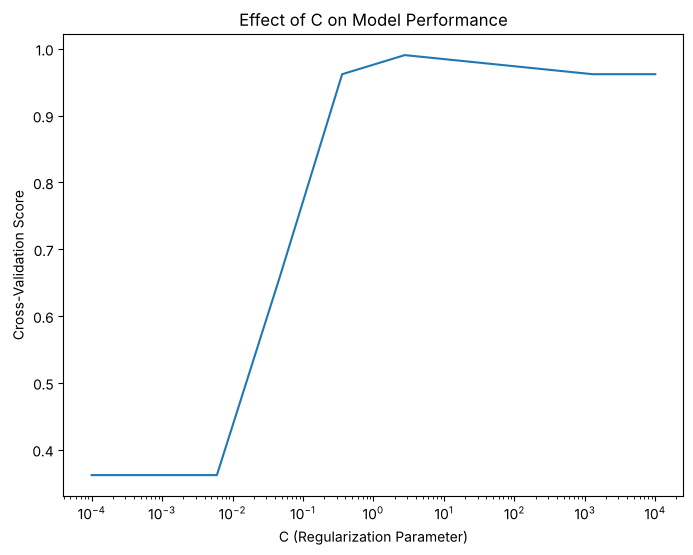

In [ ]:
# Perform a grid search with a range of C values for a specific kernel
param_grid_c = {
    'C': np.logspace(-4, 4, 10),
    'kernel': ['rbf']
}
grid_search_c = GridSearchCV(SVC(), param_grid_c, cv=5)
grid_search_c.fit(X_train, y_train)

# Plot the cross-validation scores against C values
plt.figure(figsize=(8, 6))
plt.plot(grid_search_c.param_grid['C'], grid_search_c.cv_results_['mean_test_score'])
plt.xscale('log')
plt.xlabel('C (Regularization Parameter)')
plt.ylabel('Cross-Validation Score')
plt.title('Effect of C on Model Performance')
plt.show()

In [ ]:
for c, s in zip(grid_search_c.param_grid['C'], grid_search_c.cv_results_['mean_test_score']):
    print(f'C = {c:>10.4f} -> CV accuracy = {s:.3f}')

C =     0.0001 -> CV accuracy = 0.362
C =     0.0008 -> CV accuracy = 0.362
C =     0.0060 -> CV accuracy = 0.362
C =     0.0464 -> CV accuracy = 0.657
C =     0.3594 -> CV accuracy = 0.962
C =     2.7826 -> CV accuracy = 0.990
C =    21.5443 -> CV accuracy = 0.981
C =   166.8101 -> CV accuracy = 0.971
C =  1291.5497 -> CV accuracy = 0.962
C = 10000.0000 -> CV accuracy = 0.962


**Interpretasi.** Kurva ini memperlihatkan bias–variance trade-off pada `C` dengan jelas:
- $C \le 0{,}006$: akurasi CV ≈ 0,36, setara selalu menebak kelas terbanyak. Regularisasi terlalu kuat sehingga model **underfit** total.
- $C \approx 0{,}05$–$0{,}36$: akurasi naik tajam.
- $C \approx 2{,}8$: puncak akurasi ≈ 0,99.
- $C$ lebih besar: akurasi sedikit turun (≈0,96–0,97) karena margin menjadi sempit dan model mulai menyesuaikan diri dengan titik-titik yang berada di daerah tumpang tindih (**overfitting** ringan).

## Resep 4 — SVM di Ruang Berdimensi Tinggi

### Teori
Mengapa SVM cocok untuk data "lebar" (fitur banyak dibanding sampel)?
1. **Kompleksitas tergantung margin, bukan dimensi.** Teori pembelajaran statistik (Vapnik) menunjukkan batas galat generalisasi SVM ditentukan oleh rasio $R^2/\gamma^2$ (jari-jari data terhadap margin), bukan langsung oleh jumlah fitur.
2. **Solusi sparse.** Model hanya bergantung pada support vectors.
3. **Formulasi dual** bekerja pada matriks kernel $n\times n$, sehingga biaya komputasi lebih bergantung pada jumlah sampel daripada jumlah fitur.

Di dimensi tinggi, data hampir selalu terpisah linear (dengan $p \ge n$, $n$ titik dalam posisi umum selalu bisa dipisahkan sebuah hyperplane), sehingga kernel **linear** sering sudah cukup — dan justru kernel yang terlalu fleksibel mudah overfitting.

### Persiapan — data sintetis 1000 sampel × 1000 fitur (hanya 50 informatif)

In [ ]:
# Load the libraries
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd
import numpy as np

# Create a synthetic high-dimensional dataset
X, y = make_classification(n_samples=1000, n_features=1000, n_informative=50, n_redundant=0, random_state=2024)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [ ]:
# Load the model
svm_model = SVC(kernel='linear')

# Train the model
svm_model.fit(X_train, y_train)

# Make predictions
y_pred = svm_model.predict(X_test)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
report_df = pd.DataFrame(classification_report(y_test, y_pred, output_dict=True)).transpose()

# Stylize the DataFrame
styled_report_df = (report_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

print(f"Accuracy: {accuracy:.2f}")
styled_report_df

Accuracy: 0.75


,precision,recall,f1-score,support
0,0.765,0.765,0.765,162
1,0.725,0.725,0.725,138
accuracy,0.747,0.747,0.747,1
macro avg,0.745,0.745,0.745,300
weighted avg,0.747,0.747,0.747,300


In [ ]:
print('Support vectors: %d dari %d sampel latih' % (svm_model.n_support_.sum(), len(X_train)))
print('Akurasi latih  : %.3f' % svm_model.score(X_train, y_train))

Support vectors: 433 dari 700 sampel latih
Akurasi latih  : 1.000


**Interpretasi.** Akurasi data uji hanya 0,75, padahal akurasi latih **1,000**. Dengan 1.000 fitur untuk 700 sampel latih ($p > n$), data latih **selalu** dapat dipisahkan sempurna oleh hyperplane, sehingga SVM linear dengan `C=1` menghafal data latih. Sebanyak 433 dari 700 sampel menjadi support vector — tanda bahwa margin yang ditemukan tidak "bersih". Karena hanya 50 dari 1.000 fitur yang informatif, 950 fitur noise menyediakan banyak arah palsu untuk memisahkan data latih.

Perbaikan yang mungkin: memperkecil `C` (regularisasi lebih kuat), seleksi fitur (misal `SelectKBest` atau L1-SVM `LinearSVC(penalty='l1')`), atau reduksi dimensi. Pesan pentingnya: SVM memang **bisa** bekerja pada data berdimensi tinggi, tetapi tetap butuh regularisasi yang tepat ketika rasio sinyal terhadap noise rendah.

### Visualisasi dengan PCA

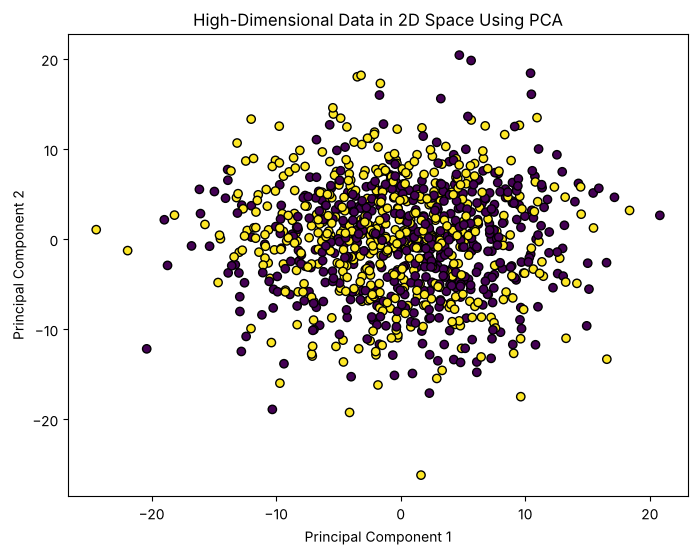

In [ ]:
# Import PCA from sklearn.decomposition
from sklearn.decomposition import PCA

# Apply PCA to reduce dimensionality
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Plot the reduced data
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, edgecolors='k', marker='o')
plt.title("High-Dimensional Data in 2D Space Using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

**Interpretasi.** Pada proyeksi 2 komponen utama, kedua kelas hampir sepenuhnya bertumpuk. Ini **tidak** berarti data tidak bisa dipisahkan: informasi pemisah tersebar di 50 dimensi informatif, sedangkan PCA tanpa label hanya menangkap arah varians terbesar, yang di sini didominasi oleh 950 fitur noise. Ini mengingatkan kembali keterbatasan PCA dari Bab 3: varians terbesar tidak sama dengan arah yang paling memisahkan kelas.

## Resep 5 — Mengevaluasi Model SVM

### Teori
SVM secara alami **tidak** menghasilkan probabilitas — keluarannya adalah skor jarak bertanda $f(\mathbf x)$ (`decision_function`). Dengan `probability=True`, scikit-learn melakukan **Platt scaling**: memasang regresi logistik pada skor SVM,
$$P(y=1\mid\mathbf x) = \frac{1}{1+\exp\big(A\,f(\mathbf x)+B\big)},$$
dengan $A, B$ dilatih lewat cross-validation internal 5-fold. Konsekuensinya: pelatihan lebih lambat, dan dalam kasus tertentu `predict_proba` bisa sedikit tidak konsisten dengan `predict`. Untuk kurva ROC, `decision_function` sebenarnya sudah cukup karena ROC hanya membutuhkan **urutan** skor.

### Persiapan — dataset Breast Cancer

In [ ]:
# Load the libraries
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import classification_report, roc_curve, auc
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

In [ ]:
# Load the model
svm_model = SVC(kernel='linear', probability=True)

# Train the model
svm_model.fit(X_train, y_train)

# Make predictions
y_pred = svm_model.predict(X_test)
y_prob = svm_model.predict_proba(X_test)[:, 1]

# Evaluate the model
report = classification_report(y_test, y_pred, output_dict=True)
report_df = pd.DataFrame(report).transpose()

# Stylize the DataFrame
styled_report_df = (report_df
    .style
    .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
    .format({
        'precision': '{:.3f}',
        'recall': '{:.3f}',
        'f1-score': '{:.3f}',
        'support': '{:.0f}'
    })
)

print(f"Accuracy: {accuracy:.2f}")
styled_report_df

Accuracy: 0.75


,precision,recall,f1-score,support
0,0.926,0.940,0.933,67
1,0.961,0.952,0.957,104
accuracy,0.947,0.947,0.947,1
macro avg,0.944,0.946,0.945,171
weighted avg,0.948,0.947,0.947,171


In [ ]:
from sklearn.metrics import accuracy_score
print('Akurasi SVM linear pada Breast Cancer: %.3f' % accuracy_score(y_test, y_pred))

Akurasi SVM linear pada Breast Cancer: 0.947


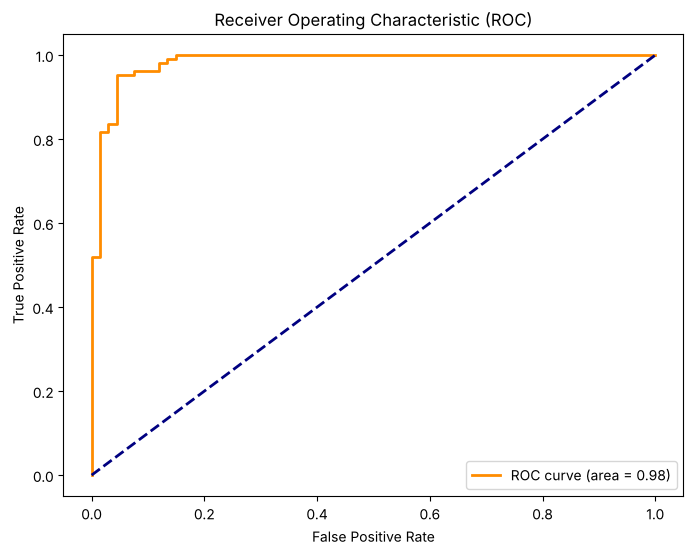

In [ ]:
# Plot the ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC)')
plt.legend(loc="lower right")
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix
print('ROC AUC: %.4f' % roc_auc)
print('Confusion matrix (baris = label sebenarnya 0/1):')
print(confusion_matrix(y_test, y_pred))

ROC AUC: 0.9841
Confusion matrix (baris = label sebenarnya 0/1):
[[63  4]
 [ 5 99]]


**Interpretasi.**
- **Catatan bug kode buku:** baris `print(f"Accuracy: {accuracy:.2f}")` mencetak 0,75, yaitu variabel `accuracy` yang masih tersisa dari Resep 4 (data berdimensi tinggi), karena sel ini tidak menghitung ulang akurasinya. Akurasi SVM linear yang sebenarnya pada Breast Cancer adalah ≈ 0,947. Bug seperti ini umum terjadi di notebook karena variabel global "bocor" antar-sel — salah satu alasan untuk menjalankan ulang notebook dari atas (*Restart & Run All*) sebelum menarik kesimpulan.
- ROC AUC ≈ 0,984: skor SVM memeringkat tumor jinak dan ganas dengan hampir sempurna. Confusion matrix menunjukkan 63 dari 67 tumor ganas terdeteksi (4 lolos) dan 5 tumor jinak salah dianggap ganas. Hasil ini sedikit lebih baik daripada regresi logistik `liblinear` tanpa scaling di Bab 6 (6 ganas lolos, AUC ≈ 0,99 — AUC-nya sedikit lebih tinggi, tetapi pada ambang default kesalahannya lebih banyak).
- SVM linear tanpa scaling pada data ini relatif lambat dilatih dan sensitif terhadap fitur berskala besar; lihat Latihan 2 untuk dampak standardisasi.

## Latihan Praktik

### Latihan 1 — Classifier SVM sederhana (Iris)

In [ ]:
# Load the libraries
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.datasets import load_iris
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Load the dataset
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train a SVM classifier
svm_model = SVC(kernel='linear')
svm_model.fit(X_train, y_train)

# Make predictions
y_pred = svm_model.predict(X_test)

# Evaluate performance
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print(f"Accuracy: {accuracy:.2f}")
print("Classification Report:")
print(report)

Accuracy: 0.93
Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        18
           1       0.91      0.83      0.87        12
           2       0.88      0.93      0.90        15

    accuracy                           0.93        45
   macro avg       0.93      0.92      0.92        45
weighted avg       0.93      0.93      0.93        45



**Interpretasi.** Hasilnya identik dengan Resep 1 karena data, pembagian (`random_state=2024`), dan model (`SVC(kernel='linear')`) sama — contoh reproduksibilitas.

### Latihan 2 — Grid search SVM pada Breast Cancer

In [ ]:
# Load the libraries
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

# Load the dataset
data = load_breast_cancer()
X = data.data
y = data.target
feature_names = data.feature_names
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Define a hyperparameter for grid search
param_grid = {
    'C': [0.1, 1, 10],
    'kernel': ['linear', 'rbf', 'poly'],
    'degree': [2, 3, 4]
}

# Perform grid search with cross-validation
grid_search = GridSearchCV(SVC(), param_grid, cv=5)
grid_search.fit(X_train, y_train)


# Train a new model with the best hyperparameters
best_model = SVC(**grid_search.best_params_)
best_model.fit(X_train, y_train)

# Make predictions with the best model
y_pred_best = best_model.predict(X_test)

# Evaluate the best model
accuracy_best = accuracy_score(y_test, y_pred_best)
report_best = classification_report(y_test, y_pred_best)
print(f"Best Model Accuracy: {accuracy_best:.2f}")
print("Best Model Classification Report:")
print(report_best)

Best Model Accuracy: 0.95
Best Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.94      0.93        67
           1       0.96      0.95      0.96       104

    accuracy                           0.95       171
   macro avg       0.94      0.95      0.94       171
weighted avg       0.95      0.95      0.95       171



In [ ]:
print('Parameter terbaik:', grid_search.best_params_)
print('Skor CV terbaik  : %.3f' % grid_search.best_score_)

# Perbandingan: SVM RBF dengan standardisasi (tanpa tuning)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
scaled_svm = make_pipeline(StandardScaler(), SVC(kernel='rbf')).fit(X_train, y_train)
print('SVM RBF + StandardScaler (tanpa tuning): %.3f' % scaled_svm.score(X_test, y_test))

Parameter terbaik: {'C': 1, 'degree': 2, 'kernel': 'linear'}
Skor CV terbaik  : 0.962
SVM RBF + StandardScaler (tanpa tuning): 0.982


**Interpretasi.** Pada data **tanpa scaling**, grid search memilih kernel `linear` dengan `C=1` (CV ≈ 0,96) dan akurasi uji 0,95. Kernel RBF dan poly tidak terpilih karena tanpa standardisasi, jarak/perkalian titik didominasi fitur berskala ribuan (`mean area`, `worst area`), sehingga kernel non-linear bekerja buruk.

Sebagai pembanding, **SVM RBF default + `StandardScaler` tanpa tuning sama sekali** mencapai akurasi 0,982 — lebih tinggi daripada model hasil grid search. Pelajaran: preprocessing yang tepat (scaling) sering lebih berdampak daripada tuning hyperparameter. Idealnya keduanya digabung: `GridSearchCV` atas sebuah `Pipeline(StandardScaler(), SVC())`.

### Latihan 3 — Visualisasi batas keputusan SVM RBF

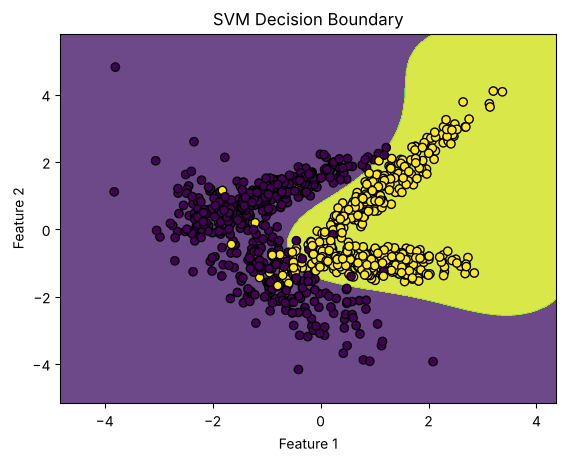

In [ ]:
# Load libraries for visualization and dataset creation
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC

# Create a synthetic dataset for binary classification
X, y = make_classification(n_samples=1000, n_features=2, n_classes=2, n_informative=2, n_redundant=0, random_state=2024)

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=2024)

# Create and train an SVM model
svm_model = SVC(kernel='rbf')
svm_model.fit(X_train, y_train)

# Create a mesh grid for plotting decision boundaries
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                     np.arange(y_min, y_max, 0.01))

# Predict class probabilities across the grid
Z = svm_model.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)

# Plot decision boundaries
plt.contourf(xx, yy, Z, alpha=0.8)
plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', marker='o')
plt.title("SVM Decision Boundary")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.show()

In [ ]:
print('Akurasi data uji SVM RBF: %.3f' % svm_model.score(X_test, y_test))
print('Jumlah support vectors  : %d dari %d' % (svm_model.n_support_.sum(), len(X_train)))

Akurasi data uji SVM RBF: 0.977
Jumlah support vectors  : 118 dari 700


**Interpretasi.** Dataset ini **sama persis** dengan Latihan 3 Bab 6 (`make_classification(..., random_state=2024)`), sehingga hasilnya bisa dibandingkan langsung:

| Model | Bentuk batas | Akurasi uji |
|---|---|---|
| Regresi logistik (Bab 6) | garis lurus | 0,897 |
| SVM RBF (bab ini) | melengkung | **0,977** |

Lonjakan akurasi ini terjadi karena `make_classification` secara default membangkitkan **2 cluster per kelas** (`n_clusters_per_class=2`), sehingga setiap kelas tersusun dari dua "gumpalan" dan tidak bisa dipisahkan secara optimal oleh satu garis lurus. Batas RBF yang melengkung dapat mengitari gumpalan-gumpalan tersebut. Ini contoh nyata kapan kernel non-linear memberi keuntungan besar.

## Kesimpulan Bab 7

- SVM memaksimalkan **margin** $2/\lVert\mathbf w\rVert$; soft-margin dengan parameter **`C`** menyeimbangkan lebar margin dan kesalahan latih (hinge loss + L2).
- Model hanya bergantung pada **support vectors**.
- **Kernel trick** memungkinkan batas non-linear dengan mengganti perkalian titik dengan $K(\mathbf x,\mathbf x')$. RBF paling fleksibel; `gamma` mengatur seberapa lokal pengaruh setiap titik.
- SVM **sensitif terhadap skala** — selalu standardisasi (terbukti pada Breast Cancer).
- SVM unggul pada data berdimensi tinggi; di sana kernel linear sering sudah cukup.
- `probability=True` memakai Platt scaling; untuk ROC cukup memakai `decision_function`.
- Tuning `C`, `kernel`, `gamma` (dan `degree`) dengan `GridSearchCV` dalam skala logaritmik.